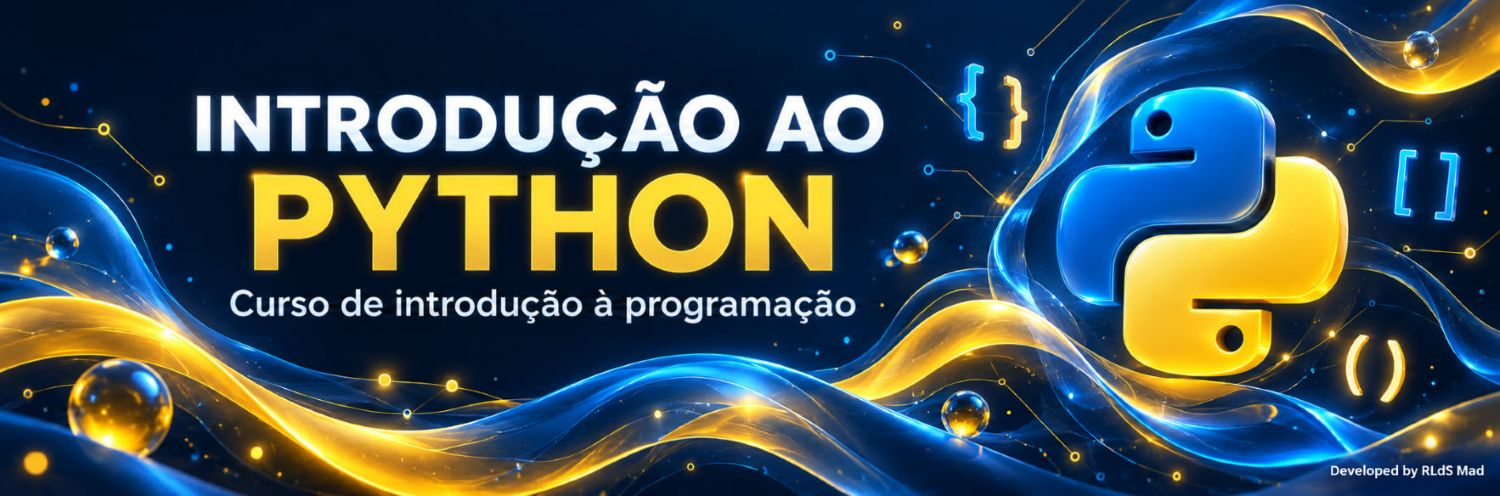

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_3_ia/N3_13_Redes_Generativas_Grafos.ipynb)

# Nível IA · Módulo 13 – Redes generativas e redes para grafos
## Autoencoders, GAN e GNN, e um mapa de todas as arquiteturas

Até aqui, as redes do tutorial aprenderam a **prever**: uma classe, um valor, a palavra seguinte. Este módulo trata de três ideias diferentes. O **autoencoder** aprende a **comprimir** os dados num código pequeno e a reconstruí-los, sem precisar de rótulos. A **GAN** aprende a **gerar** dados novos, pondo duas redes a competir. E a **rede para grafos** (GNN) aprende com dados em que o que importa são as **ligações**: redes sociais, moléculas, estradas.

Cada secção constrói a ideia de raiz em PyTorch, num exemplo pequeno que treina em segundos. O módulo fecha com uma síntese das oito arquiteturas do tutorial e um guia para escolher entre elas.

> **Objetivos:** treinar um autoencoder e interpretar o seu espaço latente; comparar a compressão de um autoencoder com a da PCA; remover ruído de imagens (*denoising*) e detetar anomalias pelo erro de reconstrução; perceber o jogo minimax entre gerador e discriminador e treinar uma GAN; reconhecer a instabilidade e o colapso de modos; implementar a passagem de mensagens e uma rede convolucional para grafos (GCN); classificar nós com poucos rótulos e perceber a sobre-suavização; escolher a arquitetura adequada a cada tipo de dados.

**Pré-requisitos:** N3_05 (PyTorch), N3_06 (os dígitos e as CNN) e N3_12 (o mapa das arquiteturas). A secção 3 usa grafos como no N3_10.

| Secção | Tema |
| --- | --- |
| 0. Preparação | PyTorch, bibliotecas e vocabulário |
| 1. Autoencoders | comprimir, reconstruir, limpar |
| 2. GAN: duas redes em competição | gerar dados novos |
| 3. Redes para grafos (GNN) | passagem de mensagens e GCN |
| 4. Síntese: as oito arquiteturas | um mapa e um guia de escolha |
| 5. Experimenta | três exercícios com solução |

## 0. Preparação

### 0.1 PyTorch e bibliotecas

No **Colab**, o PyTorch já vem instalado. No teu computador, segue as instruções do N3_05 (secção 0.1). Todas as redes deste módulo treinam no CPU em poucos segundos.

In [1]:
# Executar esta célula

import math
import time

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

try:
    import torch
    from torch import nn
except ImportError:
    raise ImportError("O PyTorch não está instalado. Vê a secção 0.1 do N3_05.")

plt.rcParams.update({"figure.dpi": 100})
torch.manual_seed(0)
np.random.seed(0)
print(f"PyTorch {torch.__version__} | networkx {nx.__version__}")

PyTorch 2.15.0+cu132 | networkx 3.7


### 0.2 Vocabulário

| Termo | Significado |
| --- | --- |
| **Codificador** / **descodificador** | as duas metades de um autoencoder: a primeira comprime, a segunda reconstrói |
| **Espaço latente** | o espaço dos códigos comprimidos; a sua dimensão é o «gargalo» (*bottleneck*) |
| **Erro de reconstrução** | a diferença entre a entrada e a sua reconstrução |
| **Modelo generativo** | um modelo que aprende a distribuição dos dados e consegue produzir exemplos novos |
| **Gerador** / **discriminador** | as duas redes de uma GAN: uma fabrica exemplos, a outra tenta distingui-los dos reais |
| **Colapso de modos** | quando o gerador só produz parte da variedade dos dados reais |
| **Passagem de mensagens** | cada nó de um grafo atualiza a sua representação a partir das dos vizinhos |
| **Aprendizagem semi-supervisionada** | aprender com muitos exemplos, dos quais só alguns têm rótulo |

## 1. Autoencoders

### 1.1 A ideia: aprender a comprimir

Um **autoencoder** é uma rede treinada para reproduzir a própria entrada: $\hat{x} = \text{Dec}(\text{Enc}(x))$. Parece inútil, mas há um truque: a camada do meio é **mais pequena** do que a entrada. Para reconstruir uma imagem de 64 píxeis a partir de, digamos, 2 números, a rede tem de descobrir o que é essencial nos dados e deitar fora o resto. Não precisa de rótulos: a própria entrada é o alvo, por isso é um método **não supervisionado**.

Usamos os 1797 dígitos de 8 × 8 píxeis do N3_06, com as intensidades em [0, 1]. O codificador e o descodificador são redes densas pequenas; a saída usa uma sigmoide, para ficar também entre 0 e 1.

In [2]:
# Executar esta célula

digitos = load_digits()
X = torch.tensor(digitos.data / 16, dtype=torch.float32)  # 1797 x 64, valores em [0, 1]
X_treino, X_teste, y_treino, y_teste = train_test_split(X, digitos.target, test_size=0.25, random_state=0,
                                                        stratify=digitos.target)


class Autoencoder(nn.Module):
    def __init__(self, latente=2):
        super().__init__()
        self.codificador = nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, latente))
        self.descodificador = nn.Sequential(nn.Linear(latente, 32), nn.ReLU(), nn.Linear(32, 64), nn.Sigmoid())

    def forward(self, x):
        return self.descodificador(self.codificador(x))


def treinar_autoencoder(modelo, dados, ruido=0.0, epocas=200, semente=0):
    torch.manual_seed(semente)
    otimizador = torch.optim.Adam(modelo.parameters(), lr=3e-3)
    for epoca in range(epocas):
        ordem = torch.randperm(len(dados))
        for i in range(0, len(dados), 128):
            lote = dados[ordem[i:i + 128]]
            entrada = (lote + ruido * torch.randn_like(lote)).clamp(0, 1)  # com ruído na secção 1.4
            otimizador.zero_grad()
            nn.functional.mse_loss(modelo(entrada), lote).backward()  # o alvo é a imagem limpa
            otimizador.step()
    return modelo


inicio = time.process_time()
ae2 = treinar_autoencoder(Autoencoder(latente=2), X_treino)
with torch.no_grad():
    print(f"Erro de reconstrução no teste (latente 2): {nn.functional.mse_loss(ae2(X_teste), X_teste):.4f} "
          f"| {time.process_time() - inicio:.1f} s")

Erro de reconstrução no teste (latente 2): 0.0396 | 5.7 s


### 1.2 O espaço latente

Com um gargalo de 2 números, cada dígito fica um ponto num plano. O autoencoder nunca viu os rótulos, mas, se pintarmos os pontos com o algarismo verdadeiro, os dígitos iguais ficam juntos: a rede descobriu sozinha a estrutura dos dados. Ao lado, algumas reconstruções: com só 2 números, são desfocadas, mas reconhecíveis.

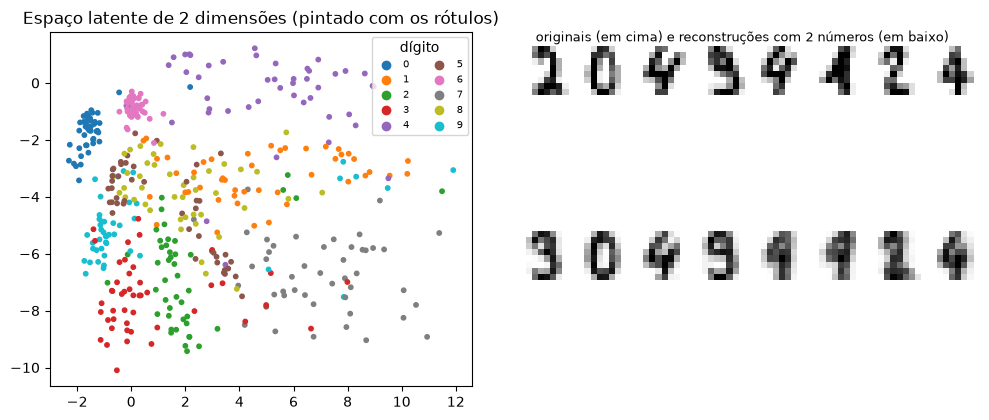

In [3]:
# Executar esta célula

with torch.no_grad():
    codigos = ae2.codificador(X_teste).numpy()
    reconstrucoes = ae2(X_teste[:8]).numpy()

fig = plt.figure(figsize=(12, 4.6))
ax = fig.add_subplot(1, 2, 1)
pontos = ax.scatter(codigos[:, 0], codigos[:, 1], c=y_teste, cmap="tab10", s=10)
ax.legend(*pontos.legend_elements(), title="dígito", fontsize=7, loc="best", ncol=2)
ax.set_title("Espaço latente de 2 dimensões (pintado com os rótulos)")
for k in range(8):
    for linha, imagem in enumerate((X_teste[k].numpy(), reconstrucoes[k])):
        a = fig.add_subplot(4, 16, 9 + k + 32 * linha)
        a.imshow(imagem.reshape(8, 8), cmap="gray_r")
        a.axis("off")
fig.text(0.53, 0.86, "originais (em cima) e reconstruções com 2 números (em baixo)", fontsize=9)
plt.show()

### 1.3 Autoencoder contra PCA

A **análise de componentes principais** (PCA), um método linear clássico, também comprime dados num número menor de dimensões. Um autoencoder com camadas **lineares** e erro quadrático aprende essencialmente o mesmo subespaço que a PCA; com ativações não lineares (ReLU), pode fazer melhor. Comparamos o erro de reconstrução no teste para gargalos de 2, 8 e 16 dimensões:

In [4]:
# Executar esta célula

linhas = []
for latente in (2, 8, 16):
    ae = treinar_autoencoder(Autoencoder(latente), X_treino)
    with torch.no_grad():
        erro_ae = nn.functional.mse_loss(ae(X_teste), X_teste).item()
    pca = PCA(latente).fit(X_treino.numpy())
    reconstruido = pca.inverse_transform(pca.transform(X_teste.numpy()))
    erro_pca = float(((reconstruido - X_teste.numpy()) ** 2).mean())
    linhas.append({"dimensões latentes": latente, "erro PCA": round(erro_pca, 4), "erro autoencoder": round(erro_ae, 4)})
pd.DataFrame(linhas).set_index("dimensões latentes")

,erro PCA,erro autoencoder
dimensões latentes,,
2,0.0530,0.0421
8,0.0246,0.0157
16,0.0115,0.0089


O autoencoder reconstrói melhor do que a PCA em todos os tamanhos, com cerca de 20 % a 35 % menos erro: uma compressão não linear aproveita melhor o espaço disponível. Com 16 dimensões, ambos reconstroem bem e a diferença absoluta já é pequena: a PCA, mais simples e sem treino, fica perto.

### 1.4 Limpar ruído (*denoising*)

Um ***denoising autoencoder*** recebe a imagem com ruído e é treinado para devolver a imagem **limpa**. Para isso, tem de aprender como é um dígito «normal» e ignorar o que não encaixa. Treinamos com ruído gaussiano de desvio 0,3 nas entradas:

Erro da imagem com ruído: 0.0522 | depois de limpar: 0.0225


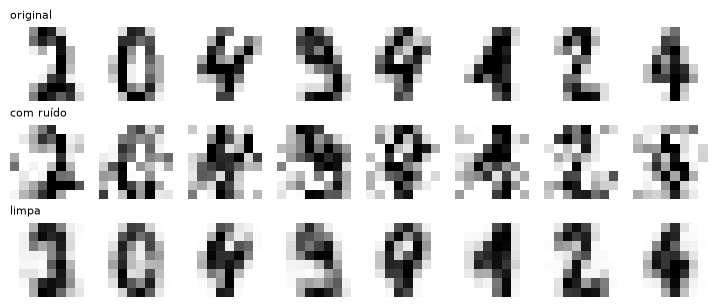

In [5]:
# Executar esta célula

limpador = treinar_autoencoder(Autoencoder(latente=16), X_treino, ruido=0.3)
torch.manual_seed(1)
com_ruido = (X_teste + 0.3 * torch.randn_like(X_teste)).clamp(0, 1)
with torch.no_grad():
    limpo = limpador(com_ruido)
print(f"Erro da imagem com ruído: {nn.functional.mse_loss(com_ruido, X_teste):.4f} | "
      f"depois de limpar: {nn.functional.mse_loss(limpo, X_teste):.4f}")

fig, eixos = plt.subplots(3, 8, figsize=(9, 3.6))
for k in range(8):
    for linha, (imagem, titulo) in enumerate(((X_teste[k], "original"), (com_ruido[k], "com ruído"), (limpo[k], "limpa"))):
        eixos[linha, k].imshow(imagem.numpy().reshape(8, 8), cmap="gray_r")
        eixos[linha, k].axis("off")
        if k == 0:
            eixos[linha, k].set_title(titulo, fontsize=8, loc="left")
plt.show()

O erro cai para menos de metade. Os autoencoders têm muitos outros usos: **detetar anomalias** (o exercício 1), pré-treinar redes quando há poucos rótulos e, na versão probabilística (o **autoencoder variacional**, VAE), gerar dados novos amostrando o espaço latente. É uma das peças centrais dos modelos de difusão que geram imagens.

## 2. GAN: duas redes em competição

### 2.1 A ideia

Uma **rede adversarial generativa** (GAN, Goodfellow et al., 2014) aprende a gerar dados novos pondo duas redes a competir:

- o **gerador** $G$ recebe ruído aleatório $z$ e produz um exemplo falso $G(z)$;
- o **discriminador** $D$ recebe um exemplo, real ou falso, e estima a probabilidade de ser real.

O discriminador é treinado para acertar; o gerador é treinado para o enganar. Formalmente, é um jogo *minimax*:

$$\min_G \max_D \; \mathbb{E}_{x}[\log D(x)] + \mathbb{E}_{z}[\log(1 - D(G(z)))]$$

Como um falsificador e um perito, cada um melhora porque o outro melhora. Se tudo correr bem, no fim o gerador produz exemplos indistinguíveis dos reais e o discriminador fica reduzido a adivinhar (D ≈ 0,5).

### 2.2 Os dados: um anel de oito gaussianas

Para ver o que acontece, usamos dados em **duas dimensões**: pontos à volta de 8 centros dispostos num anel. É um teste clássico, porque os dados têm 8 **modos** (grupos) bem separados, e uma GAN tem tendência para cobrir só alguns.

In [6]:
# Executar esta célula

ANGULOS = torch.arange(8) * 2 * math.pi / 8
CENTROS = torch.stack([2 * torch.cos(ANGULOS), 2 * torch.sin(ANGULOS)], dim=1)


def amostras_reais(n, gerador):
    escolha = torch.randint(0, 8, (n,), generator=gerador)
    return CENTROS[escolha] + 0.05 * torch.randn(n, 2, generator=gerador)


def modos_cobertos(amostras, raio=0.3, minimo=20):
    # Quantos dos 8 centros recebem pelo menos `minimo` pontos a menos de `raio`, e que fração dos pontos fica perto de algum.
    distancia = torch.cdist(amostras, CENTROS)
    perto = distancia.min(dim=1).values < raio
    contagem = torch.bincount(distancia.argmin(dim=1)[perto], minlength=8)
    return int((contagem >= minimo).sum()), perto.float().mean().item()


reais = amostras_reais(1000, torch.Generator().manual_seed(0))
print("Dados reais: modos cobertos e fração de pontos perto de um centro:", modos_cobertos(reais))

Dados reais: modos cobertos e fração de pontos perto de um centro: (8, 1.0)


### 2.3 Treinar a GAN

As duas redes são pequenas redes densas. Em cada passo, primeiro o discriminador aprende a separar reais (rótulo 1) de falsos (rótulo 0); depois o gerador aprende a fazer o discriminador dizer «real» aos seus falsos. Repara no `detach()` no passo do discriminador: aí, o gerador não deve ser atualizado. Usamos o Adam com $\beta_1 = 0{,}5$, uma escolha habitual nas GAN, que ajuda a estabilidade.

Treino: 12.5 s


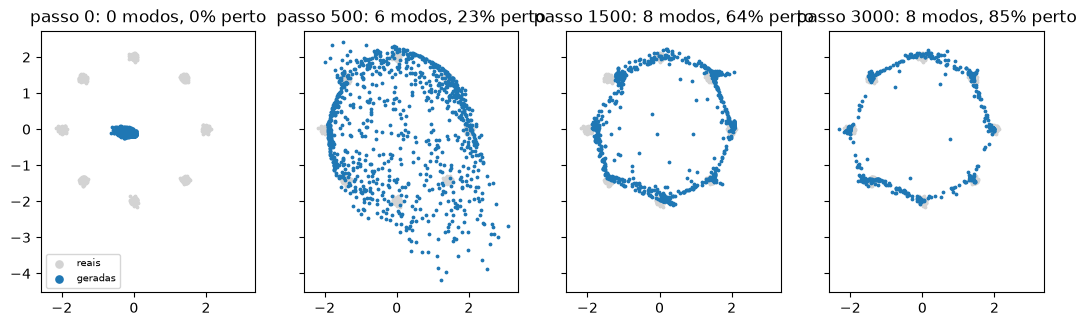

In [7]:
# Executar esta célula

def treinar_gan(passos=3000, semente=0, guardar=(0, 500, 1500, 3000)):
    torch.manual_seed(semente)
    gerador_aleatorio = torch.Generator().manual_seed(semente)
    G = nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 2))
    D = nn.Sequential(nn.Linear(2, 64), nn.LeakyReLU(0.2), nn.Linear(64, 64), nn.LeakyReLU(0.2), nn.Linear(64, 1))
    otim_G = torch.optim.Adam(G.parameters(), lr=1e-3, betas=(0.5, 0.999))
    otim_D = torch.optim.Adam(D.parameters(), lr=1e-3, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    um, zero = torch.ones(128, 1), torch.zeros(128, 1)
    instantaneos = {}
    for passo in range(passos + 1):
        reais = amostras_reais(128, gerador_aleatorio)
        falsos = G(torch.randn(128, 2))
        otim_D.zero_grad()  # 1. o discriminador aprende a separar
        (bce(D(reais), um) + bce(D(falsos.detach()), zero)).backward()
        otim_D.step()
        otim_G.zero_grad()  # 2. o gerador aprende a enganar
        bce(D(falsos), um).backward()
        otim_G.step()
        if passo in guardar:
            with torch.no_grad():
                instantaneos[passo] = G(torch.randn(1000, 2))
    return G, D, instantaneos


inicio = time.process_time()
G, D, instantaneos = treinar_gan(semente=0)
print(f"Treino: {time.process_time() - inicio:.1f} s")

fig, eixos = plt.subplots(1, 4, figsize=(13, 3.4), sharex=True, sharey=True)
for ax, (passo, amostras) in zip(eixos, instantaneos.items()):
    ax.scatter(reais[:, 0], reais[:, 1], s=3, color="lightgray", label="reais")
    ax.scatter(amostras[:, 0], amostras[:, 1], s=3, color="tab:blue", label="geradas")
    modos, fracao = modos_cobertos(amostras)
    ax.set_title(f"passo {passo}: {modos} modos, {fracao:.0%} perto")
    ax.set_aspect("equal")
eixos[0].legend(loc="lower left", fontsize=7, markerscale=3)
plt.show()

No passo 0, o gerador produz uma mancha sem forma. Ao fim de 500 passos já encontrou parte dos grupos; aos 1500 cobre os 8; aos 3000, a grande maioria dos pontos gerados cai junto de um centro. O gerador nunca viu um ponto real: aprendeu a distribuição só através das respostas do discriminador.

### 2.4 Instabilidade e colapso de modos

As GAN são famosas por serem **difíceis de treinar**. Não há uma perda que desça de forma regular, porque cada rede muda o problema da outra; o resultado depende da semente, dos ritmos de aprendizagem e do equilíbrio entre as duas redes. O problema mais típico é o **colapso de modos**: o gerador descobre um tipo de exemplo que engana o discriminador e passa a produzir só esse, abandonando a variedade dos dados. Repetimos o treino com outras sementes:

In [8]:
# Executar esta célula

linhas = []
for semente in range(3):
    _, _, inst = treinar_gan(semente=semente)
    linhas.append({"semente": semente, **{f"passo {p}": "{} modos, {:.0%} perto".format(*modos_cobertos(a)) for p, a in inst.items()}})
pd.DataFrame(linhas).set_index("semente")

,passo 0,passo 500,passo 1500,passo 3000
semente,,,,
0,"0 modos, 0% perto","6 modos, 23% perto","8 modos, 64% perto","8 modos, 85% perto"
1,"0 modos, 0% perto","6 modos, 21% perto","8 modos, 75% perto","7 modos, 91% perto"
2,"0 modos, 0% perto","0 modos, 8% perto","8 modos, 64% perto","8 modos, 83% perto"


O percurso muda com a semente: numa delas, aos 500 passos o gerador ainda não tinha encontrado nenhum modo; noutra, chega aos 3000 passos com só 7 dos 8 modos, depois de os ter coberto todos aos 1500. Em problemas maiores (imagens), estes efeitos são muito mais graves, e foram precisas muitas técnicas para os domar: funções de perda alternativas (como a da WGAN), normalização espectral, e arquiteturas cuidadosas. Hoje, para gerar imagens, os **modelos de difusão** substituíram em grande parte as GAN, precisamente por serem mais estáveis. A ideia adversarial continua, no entanto, a ser usada em muitos contextos.

## 3. Redes para grafos (GNN)

### 3.1 A ideia: passagem de mensagens

Num grafo (N3_10), os dados são nós ligados por arestas. Uma rede densa trataria cada nó isoladamente; uma CNN precisa de uma grelha regular. As **redes neuronais para grafos** usam a ideia de **passagem de mensagens**: em cada camada, cada nó recolhe as representações dos vizinhos, junta-as e atualiza a sua:

$$h_v' = \varphi\Big(h_v,\; \textstyle\sum_{u \in \mathcal{N}(v)} h_u\Big)$$

Depois de $k$ camadas, cada nó «sabe» o que se passa até $k$ arestas de distância. O viés indutivo é: **nós ligados tendem a ser parecidos** (*homofilia*). É o mesmo princípio da CNN (combinar a vizinhança) generalizado a vizinhanças irregulares.

A versão mais conhecida é a **rede convolucional para grafos** (GCN, Kipf e Welling, 2017). Com a matriz de adjacência $A$ (com auto-laços: $\tilde{A} = A + I$, para cada nó contar consigo próprio) e a matriz diagonal dos graus $\tilde{D}$, uma camada é:

$$H' = \sigma\big(\hat{A}\, H\, W\big), \qquad \hat{A} = \tilde{D}^{-1/2}\, \tilde{A}\, \tilde{D}^{-1/2}$$

$HW$ transforma as características de cada nó (como numa camada densa); multiplicar por $\hat{A}$ faz a média ponderada com os vizinhos. A normalização impede que nós com muitos vizinhos fiquem com valores enormes.

### 3.2 O clube de karaté de Zachary

Usamos um conjunto de dados **real** e clássico, que vem com a `networkx`: a rede de amizades entre os 34 membros de um clube de karaté universitário, registada pelo antropólogo Wayne Zachary nos anos 70. Durante o estudo, um conflito entre o instrutor (nó 0) e o presidente (nó 33) dividiu o clube em dois. A pergunta: **conhecendo só o lado destes dois, conseguimos prever para que lado foi cada um dos outros 32, só pelas amizades?**

34 membros, 78 amizades | lado do instrutor: 17, do presidente: 17


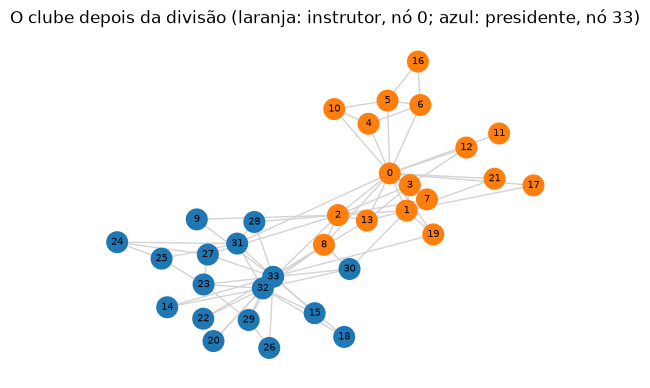

In [9]:
# Executar esta célula

clube = nx.karate_club_graph()
n = clube.number_of_nodes()
lado = torch.tensor([0 if clube.nodes[v]["club"] == "Mr. Hi" else 1 for v in clube])
print(f"{n} membros, {clube.number_of_edges()} amizades | lado do instrutor: {(lado == 0).sum().item()}, "
      f"do presidente: {(lado == 1).sum().item()}")

posicoes = nx.spring_layout(clube, seed=3)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
nx.draw_networkx(clube, posicoes, ax=ax, node_color=["tab:orange" if l == 0 else "tab:blue" for l in lado],
                 node_size=220, font_size=7, edge_color="lightgray")
ax.set_title("O clube depois da divisão (laranja: instrutor, nó 0; azul: presidente, nó 33)")
ax.axis("off")
plt.show()

### 3.3 Uma GCN de raiz

Os nós não têm características próprias (não sabemos idades nem nada sobre os membros), por isso cada nó recebe um vetor *one-hot* com a sua identidade: a matriz identidade. Toda a informação útil vem, portanto, das **ligações**. Treinamos com os rótulos de **dois** nós apenas (o 0 e o 33) e avaliamos nos outros 32: é aprendizagem **semi-supervisionada**.

Para mostrar o papel do grafo, a mesma rede pode correr sem ele (`usar_grafo=False`, trocando $\hat{A}$ pela identidade), o que a transforma numa rede densa comum.

In [10]:
# Executar esta célula

A_til = torch.tensor(nx.to_numpy_array(clube, weight=None), dtype=torch.float32) + torch.eye(n)  # com auto-laços
grau = A_til.sum(dim=1)
A_hat = grau.pow(-0.5)[:, None] * A_til * grau.pow(-0.5)[None, :]  # normalização simétrica


class GCN(nn.Module):
    def __init__(self, entrada, escondida=16, saida=2, usar_grafo=True):
        super().__init__()
        self.camada1, self.camada2 = nn.Linear(entrada, escondida), nn.Linear(escondida, saida)
        self.usar_grafo = usar_grafo

    def forward(self, X):
        P = A_hat if self.usar_grafo else torch.eye(len(X))
        h = torch.relu(P @ self.camada1(X))  # transformar e juntar com os vizinhos
        return P @ self.camada2(h)


caracteristicas = torch.eye(n)  # cada nó só se conhece a si próprio
rotulados = torch.tensor([0, 33])
avaliar = torch.ones(n, dtype=torch.bool)
avaliar[rotulados] = False


def treinar_gcn(usar_grafo, semente=0, epocas=200):
    torch.manual_seed(semente)
    modelo = GCN(n, usar_grafo=usar_grafo)
    otimizador = torch.optim.Adam(modelo.parameters(), lr=0.01, weight_decay=5e-4)
    for epoca in range(epocas):
        otimizador.zero_grad()
        nn.functional.cross_entropy(modelo(caracteristicas)[rotulados], lado[rotulados]).backward()
        otimizador.step()
    with torch.no_grad():
        previsto = modelo(caracteristicas).argmax(dim=1)
    return modelo, previsto, (previsto[avaliar] == lado[avaliar]).float().mean().item()


for usar in (True, False):
    exatidoes = [treinar_gcn(usar, semente=s)[2] for s in range(5)]
    print(f"{'GCN (com o grafo)' if usar else 'Rede densa (sem o grafo)':25s}: exatidão nos 32 nós por rotular {exatidoes}")

GCN (com o grafo)        : exatidão nos 32 nós por rotular [0.96875, 0.96875, 0.96875, 0.96875, 0.96875]


Rede densa (sem o grafo) : exatidão nos 32 nós por rotular [0.5, 0.5, 0.5, 0.5, 0.5]


Com o grafo, a GCN acerta em 31 dos 32 membros (96,9 %), com apenas dois rótulos. Sem o grafo, a rede densa fica nos 50 %: com características que são só identidades, não há nada que ligue o nó 5 ao nó 0, e a rede não tem como generalizar. Toda a informação estava nas ligações. Vejamos onde está o erro:

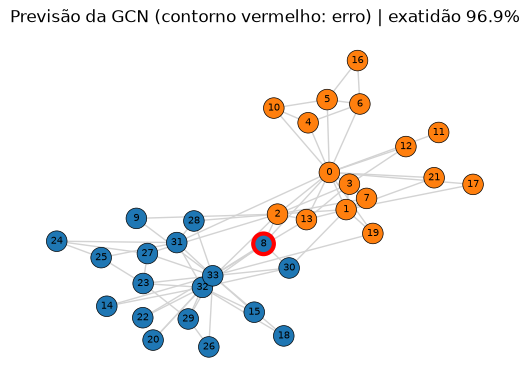

Nós errados: [8]


In [11]:
# Executar esta célula

_, previsto, exatidao = treinar_gcn(True)
cores = ["tab:orange" if p == 0 else "tab:blue" for p in previsto]
contornos = ["red" if previsto[v] != lado[v] else "black" for v in range(n)]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
nx.draw_networkx(clube, posicoes, ax=ax, node_color=cores, edgecolors=contornos, linewidths=[3 if c == "red" else 0.5 for c in contornos],
                 node_size=220, font_size=7, edge_color="lightgray")
ax.set_title(f"Previsão da GCN (contorno vermelho: erro) | exatidão {exatidao:.1%}")
ax.axis("off")
plt.show()
print("Nós errados:", [v for v in range(n) if previsto[v] != lado[v]])

O nó errado está na fronteira entre os dois grupos, com amizades dos dois lados: é exatamente o caso em que a homofilia não chega para decidir. No estudo original, o modelo de Zachary, baseado só nas ligações, também errou num único membro: o número 9 na numeração do artigo, que é este nó 8 (a `networkx` numera a partir de 0).

### 3.4 Quantas camadas? A sobre-suavização

Cada camada alarga a vizinhança em uma aresta. Seria de esperar que mais camadas fossem melhores, mas cada multiplicação por $\hat{A}$ também faz uma **média** com os vizinhos, e médias de médias tornam todos os nós cada vez mais parecidos: é a **sobre-suavização** (*over-smoothing*). Podemos vê-lo sem treinar nada: partimos de vetores aleatórios e aplicamos $\hat{A}$ repetidamente, medindo a semelhança (cosseno) média entre nós.

In [12]:
# Executar esta célula

torch.manual_seed(0)
H = torch.randn(n, 8)
fora_diagonal = ~torch.eye(n, dtype=torch.bool)
for k in (1, 2, 5, 10, 30):
    Hk = torch.linalg.matrix_power(A_hat, k) @ H
    Hk = Hk / Hk.norm(dim=1, keepdim=True)
    print(f"{k:2d} propagações: semelhança média entre nós {(Hk @ Hk.T)[fora_diagonal].mean():.3f}")

 1 propagações: semelhança média entre nós 0.168
 2 propagações: semelhança média entre nós 0.436
 5 propagações: semelhança média entre nós 0.791
10 propagações: semelhança média entre nós 0.925
30 propagações: semelhança média entre nós 0.999


Ao fim de 10 propagações, os vetores de todos os nós são quase iguais (semelhança 0,93), e ao fim de 30 indistinguíveis. Uma GCN com muitas camadas perde a capacidade de distinguir os nós (o exercício 3 mede-o). Por isso as GNN usadas na prática têm poucas camadas, normalmente 2 a 4, ou usam ligações residuais como os *transformers*.

As GNN são usadas em **química e biologia** (moléculas como grafos de átomos, para prever propriedades ou descobrir fármacos), em **recomendação** (utilizadores e produtos), em **redes de transportes** (prever tempos de viagem em mapas, como os do N3_10) e em **física** (simular partículas que interagem). E há uma ligação curiosa ao N3_12: um *transformer* é, no fundo, uma GNN num grafo **completo**, em que cada elemento troca mensagens com todos os outros, com pesos dados pela atenção.

## 4. Síntese: as oito arquiteturas

| Arquitetura | Ideia central | Fórmula-chave | Dados típicos | Pontos fortes | Limitações | No tutorial |
| --- | --- | --- | --- | --- | --- | --- |
| **MLP** | camadas densas, informação num só sentido | $y = \sigma(Wx + b)$ | tabelas | simples, universal | não aproveita estrutura; muitos parâmetros | N3_04, N3_05 |
| **CNN** | filtros que deslizam: padrões locais | $S = (I * K) + b$ | imagens, sinais, grelhas | partilha de pesos, invariância à posição | precisa de uma grelha regular | N3_06 |
| **RNN** | estado escondido que percorre a sequência | $h_t = \tanh(W_h h_{t-1} + W_x x_t)$ | sequências curtas | memória com custo $O(T)$ | gradiente desvanece; não paraleliza | N3_12 |
| **LSTM / GRU** | memória protegida por portas | $C_t = f_t \odot C_{t-1} + i_t \odot g_t$ | séries temporais, áudio | dependências bem mais longas | sequencial; memória limitada | N3_12 |
| **Transformer** | atenção: todos olham para todos | $\text{softmax}(QK^T/\sqrt{d})\,V$ | texto, código, imagem | dependências a qualquer distância, paralelo | custo $O(T^2)$; muitos dados | N3_07, N3_12 |
| **Autoencoder** | comprimir e reconstruir | $\hat{x} = \text{Dec}(\text{Enc}(x))$ | qualquer tipo, sem rótulos | não supervisionado; anomalias, ruído | reconstruções desfocadas; não gera bem (o VAE sim) | N3_13 |
| **GAN** | gerador contra discriminador | $\min_G \max_D V(D, G)$ | imagens, dados sintéticos | amostras nítidas e realistas | treino instável; colapso de modos | N3_13 |
| **GNN** | passagem de mensagens entre vizinhos | $H' = \sigma(\hat{A} H W)$ | grafos, redes, moléculas | usa as ligações; poucos rótulos | sobre-suavização; grafos enormes | N3_13 |

**Como escolher?** A primeira pergunta não é «que rede é melhor», mas **«que estrutura têm os meus dados?»**:

- uma **tabela**, sem ordem nem vizinhança entre colunas → começar por modelos clássicos (N2_04, N3_03, onde o *gradient boosting* ganhou à rede no N3_05); se for preciso, uma MLP;
- uma **grelha** (imagem, mapa, espectrograma) → CNN;
- uma **sequência** curta, ou com poucos recursos → LSTM ou GRU; longa, ou com muitos dados → *transformer* (de preferência pré-treinado, como no N3_07);
- **ligações** entre entidades → GNN;
- **sem rótulos**, para comprimir, limpar ou detetar o que é anormal → autoencoder;
- **gerar** dados novos → modelos generativos (GAN, VAE, difusão; para texto, *transformers*).

E as arquiteturas combinam-se: um modelo de imagem e texto junta uma CNN ou um *transformer* de visão com um *transformer* de texto; um modelo de difusão usa um autoencoder e uma rede com atenção. Perceber as ideias de base permite ler qualquer arquitetura nova como uma combinação das que já conheces.

## 5. Experimenta

### Exercício 1 – Detetar anomalias com um autoencoder

Treina um autoencoder com gargalo de 8 apenas com os dígitos **0 a 4** do conjunto de treino. Depois, calcula o erro de reconstrução de cada imagem do teste e compara a média dos dígitos 0–4 com a dos dígitos 5–9 (que o autoencoder nunca viu). Mede também a AUC (N2_04) do erro como «detetor» de dígitos 5–9.

In [13]:
# Executar esta célula

# Escreve aqui o código do exercício 1

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.metrics import roc_auc_score

normais = X_treino[torch.tensor(y_treino < 5)]
detetor = treinar_autoencoder(Autoencoder(latente=8), normais)
with torch.no_grad():
    erro = ((detetor(X_teste) - X_teste) ** 2).mean(dim=1)
y_t = torch.tensor(y_teste)
print(f"Erro médio: dígitos 0-4 {erro[y_t < 5].mean():.4f} | dígitos 5-9 {erro[y_t >= 5].mean():.4f}")
print(f"AUC do erro de reconstrução para detetar os dígitos 5-9: {roc_auc_score((y_t >= 5).numpy(), erro.numpy()):.3f}")
print("Erro médio por dígito:", {d: round(erro[y_t == d].mean().item(), 4) for d in range(10)})
```

Os dígitos que o autoencoder nunca viu têm um erro de reconstrução mais de três vezes maior, e o erro sozinho separa-os com uma AUC de cerca de 0,97. É o princípio da deteção de anomalias sem rótulos: treina-se só com o que é normal (transações legítimas, peças sem defeito) e desconfia-se do que a rede não consegue reconstruir. Repara que o 8 e o 7 são os dígitos «desconhecidos» com menor erro: parecem-se com dígitos conhecidos (o 8 com o 3, o 7 com o 1), e o autoencoder reconstrói-os razoavelmente.

</details>

### Exercício 2 – Uma GAN para as meias-luas

Adapta a `treinar_gan` para gerar pontos da distribuição das **meias-luas** do N3_05 (`make_moons(..., noise=0.05)` do scikit-learn), em vez do anel. Mede que fração dos pontos gerados fica a menos de 0,1 de um ponto real e desenha os dois conjuntos.

In [14]:
# Executar esta célula

# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.datasets import make_moons

torch.manual_seed(0)
G2 = nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 2))
D2 = nn.Sequential(nn.Linear(2, 64), nn.LeakyReLU(0.2), nn.Linear(64, 64), nn.LeakyReLU(0.2), nn.Linear(64, 1))
otim_G = torch.optim.Adam(G2.parameters(), lr=1e-3, betas=(0.5, 0.999))
otim_D = torch.optim.Adam(D2.parameters(), lr=1e-3, betas=(0.5, 0.999))
bce, um, zero = nn.BCEWithLogitsLoss(), torch.ones(128, 1), torch.zeros(128, 1)
for passo in range(3000):
    reais = torch.tensor(make_moons(128, noise=0.05, random_state=passo)[0], dtype=torch.float32)
    falsos = G2(torch.randn(128, 2))
    otim_D.zero_grad()
    (bce(D2(reais), um) + bce(D2(falsos.detach()), zero)).backward()
    otim_D.step()
    otim_G.zero_grad()
    bce(D2(falsos), um).backward()
    otim_G.step()

with torch.no_grad():
    gerados = G2(torch.randn(1000, 2))
referencia = torch.tensor(make_moons(2000, noise=0.05, random_state=0)[0], dtype=torch.float32)
perto = (torch.cdist(gerados, referencia).min(dim=1).values < 0.1).float().mean().item()
print(f"Pontos gerados a menos de 0,1 de um ponto real: {perto:.0%}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.scatter(referencia[:, 0], referencia[:, 1], s=3, color="lightgray", label="reais")
ax.scatter(gerados[:, 0], gerados[:, 1], s=3, color="tab:blue", label="geradas")
ax.legend()
plt.show()
```

Cerca de 94 % dos pontos gerados caem sobre as meias-luas. Só mudou a função que fornece os dados reais: o mesmo gerador e o mesmo discriminador aprendem uma distribuição com uma forma completamente diferente.

</details>

### Exercício 3 – A sobre-suavização na prática

Generaliza a `GCN` para um número qualquer de camadas e treina-a (como na secção 3.3) com 2, 6, 10 e 16 camadas, 3 sementes cada. Como varia a exatidão?

In [15]:
# Executar esta célula

# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
class GCNProfunda(nn.Module):
    def __init__(self, camadas, escondida=16):
        super().__init__()
        dimensoes = [n] + [escondida] * (camadas - 1) + [2]
        self.camadas = nn.ModuleList(nn.Linear(a, b) for a, b in zip(dimensoes, dimensoes[1:]))

    def forward(self, X):
        h = X
        for i, camada in enumerate(self.camadas):
            h = A_hat @ camada(h)
            if i < len(self.camadas) - 1:
                h = torch.relu(h)
        return h


for camadas in (2, 6, 10, 16):
    exatidoes = []
    for semente in range(3):
        torch.manual_seed(semente)
        modelo = GCNProfunda(camadas)
        otimizador = torch.optim.Adam(modelo.parameters(), lr=0.01, weight_decay=5e-4)
        for epoca in range(200):
            otimizador.zero_grad()
            nn.functional.cross_entropy(modelo(caracteristicas)[rotulados], lado[rotulados]).backward()
            otimizador.step()
        with torch.no_grad():
            exatidoes.append(round((modelo(caracteristicas).argmax(1)[avaliar] == lado[avaliar]).float().mean().item(), 3))
    print(f"{camadas:2d} camadas: exatidão {exatidoes}")
```

Com 2 camadas, 96,9 %; com 6, ainda cerca de 94 %; com 10 ou 16 camadas, a exatidão cai para perto dos 50 %, o mesmo que responder ao acaso. Os nós ficaram tão parecidos entre si que a rede deixou de os conseguir separar. Mais camadas não é sempre melhor: numa GNN, a profundidade tem de ser ajustada ao diâmetro útil do grafo (no clube, quase todos estão a 3 arestas ou menos do instrutor).

</details>

## Verifica o que aprendeste

1. Porque é que um autoencoder não precisa de rótulos? Para que serve o gargalo?
2. Que relação há entre um autoencoder e a PCA? Quando é que o autoencoder ganha?
3. Como se treina um autoencoder para remover ruído, e porque funciona?
4. Como se usa o erro de reconstrução para detetar anomalias?
5. Quais são os papéis do gerador e do discriminador numa GAN, e o que quer dizer que o treino é um jogo *minimax*?
6. Para que serve o `detach()` no passo do discriminador?
7. O que é o colapso de modos? Porque é que o treino de uma GAN é instável?
8. O que é a passagem de mensagens? Escreve a camada de uma GCN e explica o papel de $\hat{A}$.
9. No clube de karaté, porque é que a rede densa fica nos 50 % e a GCN acerta quase tudo?
10. O que é a sobre-suavização, e que consequência tem no número de camadas de uma GNN?
11. Que estrutura dos dados aproveita cada uma das oito arquiteturas da síntese?

<details>
<summary><b>Ver respostas</b></summary>

1. Porque o alvo é a própria entrada. O gargalo, mais pequeno do que a entrada, obriga a rede a guardar só o essencial, em vez de copiar.
2. Um autoencoder linear com erro quadrático aprende o mesmo subespaço que a PCA. Com ativações não lineares, consegue comprimir melhor, sobretudo quando o gargalo é muito apertado.
3. Dá-se à rede a imagem com ruído e pede-se a imagem limpa. Para reduzir o erro, a rede tem de aprender como são os dados normais e descartar o que não encaixa neles.
4. Treina-se o autoencoder só com dados normais; os exemplos que ele reconstrói mal (erro alto) são diferentes do que aprendeu e são candidatos a anomalia.
5. O gerador transforma ruído em exemplos falsos; o discriminador estima se um exemplo é real. O discriminador maximiza a sua capacidade de distinguir, o gerador minimiza-a: cada um otimiza o mesmo valor em sentidos opostos.
6. Para que o gradiente da perda do discriminador não atualize o gerador: nesse passo, só o discriminador aprende.
7. É quando o gerador produz só parte da variedade dos dados reais (alguns modos). O treino é instável porque cada rede altera o problema da outra: não há uma função de perda fixa a descer.
8. Cada nó atualiza a sua representação a partir das representações dos vizinhos. $H' = \sigma(\hat{A} H W)$: $HW$ transforma as características, e $\hat{A}$ (a adjacência com auto-laços, normalizada pelos graus) faz a média ponderada com os vizinhos.
9. Porque os nós só têm a identidade como característica: sem o grafo, nada liga um nó por rotular aos dois rotulados. A GCN propaga a informação dos rótulos pelas amizades, e os amigos tendem a ficar do mesmo lado (homofilia).
10. Cada camada faz uma média com os vizinhos; muitas camadas tornam as representações de todos os nós quase iguais, e a rede deixa de os distinguir. Por isso as GNN têm normalmente poucas camadas.
11. MLP: nenhuma (vetores); CNN: localidade numa grelha; RNN/LSTM: ordem numa sequência; *transformer*: relações entre quaisquer pares; autoencoder: os dados vivem num espaço de poucas dimensões; GAN: uma distribuição que se pode imitar; GNN: as ligações de um grafo.

</details>

## Leitura recomendada

- Goodfellow, I., Bengio, Y. e Courville, A. (2016). *[Deep Learning](https://www.deeplearningbook.org/)*. Cambridge: MIT Press. Capítulos 14 (autoencoders) e 20 (modelos generativos). Gratuito online.
- Hinton, G. E. e Salakhutdinov, R. R. (2006). [Reducing the dimensionality of data with neural networks](https://doi.org/10.1126/science.1127647). *Science*, 313(5786), 504–507. Autoencoders profundos contra a PCA.
- Goodfellow, I. et al. (2014). [Generative adversarial nets](https://arxiv.org/abs/1406.2661). *Advances in Neural Information Processing Systems*, 27.
- Kipf, T. N. e Welling, M. (2017). [Semi-supervised classification with graph convolutional networks](https://arxiv.org/abs/1609.02907). *ICLR 2017*. A GCN, incluindo o exemplo do clube de karaté.
- Zachary, W. W. (1977). [An information flow model for conflict and fission in small groups](https://doi.org/10.1086/jar.33.4.3629752). *Journal of Anthropological Research*, 33(4), 452–473. Os dados originais do clube.
- Hamilton, W. L. (2020). *[Graph Representation Learning](https://www.cs.mcgill.ca/~wlh/grl_book/)*. Morgan & Claypool. Introdução às GNN, com versão gratuita em pré-publicação.
- Zhang, A., Lipton, Z. C., Li, M. e Smola, A. J. *[Dive into Deep Learning](https://d2l.ai/)*. Capítulo sobre GAN, com código em PyTorch. Gratuito.
- **Módulos relacionados:** N3_05 (PyTorch), N3_06 (dígitos e CNN), N3_10 (grafos), N3_12 (sequências, atenção e o mapa das arquiteturas).